# Solutions to notebook 8: From symbols to numbers: `lambdify`, SciPy and code generation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/solutions/08_symbols_to_numbers.ipynb)

Worked solutions to the exercises at the end of [notebook 8](../notebooks/08_symbols_to_numbers.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, trapezoid
from scipy.optimize import curve_fit

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## Exercise 1

Fit the same data with the Freundlich isotherm $q = k\,p^{1/n}$, using a SymPy-derived
Jacobian. Which model fits better, judged by the sum of squared residuals?

First recreate the data and the Langmuir fit of section 8.3, with the same random seed.

In [2]:
p, q_max, K = sp.symbols("p q_max K", positive=True)
langmuir = q_max * K * p / (1 + K * p)

model = sp.lambdify((p, q_max, K), langmuir, "numpy")
model_jac = sp.lambdify((p, q_max, K), [sp.diff(langmuir, par) for par in (q_max, K)], "numpy")

# synthetic "measurements": true values q_max = 2.5 mol/kg, K = 0.8 1/bar, plus noise
rng = np.random.default_rng(seed=3)
p_data = np.array([0.1, 0.2, 0.5, 1, 2, 4, 6, 8, 10.0])
q_data = model(p_data, 2.5, 0.8) + rng.normal(0, 0.04, p_data.size)

best_langmuir, _ = curve_fit(model, p_data, q_data, p0=[1, 1],
                             jac=lambda p_values, *params: np.column_stack(model_jac(p_values, *params)))
best_langmuir

array([2.46083597, 0.79991041])

In [3]:
# the Freundlich model and its derivatives with respect to the two parameters
k, n = sp.symbols("k n", positive=True)
freundlich = k * p ** (1 / n)

sensitivities = [sp.diff(freundlich, par) for par in (k, n)]
sensitivities

⎡          n ___        ⎤
⎢n ___  -k⋅╲╱ p ⋅log(p) ⎥
⎢╲╱ p , ────────────────⎥
⎢               2       ⎥
⎣              n        ⎦

In [4]:
freundlich_model = sp.lambdify((p, k, n), freundlich, "numpy")
freundlich_jac = sp.lambdify((p, k, n), sensitivities, "numpy")

def jacobian(p_values, *params):
    return np.column_stack(freundlich_jac(p_values, *params))

best_freundlich, covariance = curve_fit(freundlich_model, p_data, q_data, p0=[1, 2], jac=jacobian)
errors = np.sqrt(np.diag(covariance))
print(f"k = {best_freundlich[0]:.2f} ± {errors[0]:.2f} mol/kg/bar^(1/n)     n = {best_freundlich[1]:.2f} ± {errors[1]:.2f}")

k = 1.00 ± 0.09 mol/kg/bar^(1/n)     n = 2.65 ± 0.33


In [5]:
ssr_langmuir = np.sum((q_data - model(p_data, *best_langmuir)) ** 2)
ssr_freundlich = np.sum((q_data - freundlich_model(p_data, *best_freundlich)) ** 2)
print(f"sum of squared residuals:   Langmuir {ssr_langmuir:.4f}    Freundlich {ssr_freundlich:.4f}  (mol/kg)²")

sum of squared residuals:   Langmuir 0.0208    Freundlich 0.2571  (mol/kg)²


In [6]:
# verify: the exact Jacobian agrees with finite differences, the fit without a Jacobian
# lands on the same parameters, and the Langmuir fit of the lesson is reproduced
step = 1e-6
k_fit, n_fit = best_freundlich
finite_diff = np.column_stack([
    (freundlich_model(p_data, k_fit + step, n_fit) - freundlich_model(p_data, k_fit - step, n_fit)) / (2 * step),
    (freundlich_model(p_data, k_fit, n_fit + step) - freundlich_model(p_data, k_fit, n_fit - step)) / (2 * step),
])
assert np.allclose(jacobian(p_data, k_fit, n_fit), finite_diff, atol=1e-7)

no_jacobian, _ = curve_fit(freundlich_model, p_data, q_data, p0=[1, 2])
assert np.allclose(best_freundlich, no_jacobian, rtol=1e-4)
assert np.allclose(best_langmuir, [2.46, 0.80], atol=0.01)       # values printed in the lesson
assert ssr_langmuir < ssr_freundlich

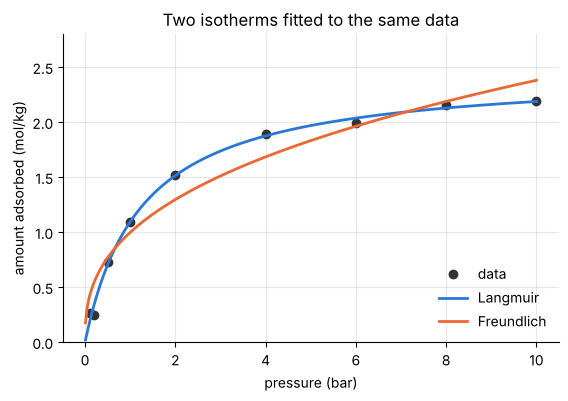

In [7]:
p_grid = np.linspace(0.01, 10, 300)
fig, ax = plt.subplots()
ax.plot(p_data, q_data, "o", color="0.2", ms=6, label="data")
ax.plot(p_grid, model(p_grid, *best_langmuir), label="Langmuir")
ax.plot(p_grid, freundlich_model(p_grid, *best_freundlich), label="Freundlich")
ax.set(xlabel="pressure (bar)", ylabel="amount adsorbed (mol/kg)", ylim=(0, 2.8), title="Two isotherms fitted to the same data")
ax.legend(frameon=False, loc="lower right");

**Answer.** The Freundlich fit gives $k \approx 1.00$ mol/kg/bar$^{1/n}$ and $n \approx 2.65$, with a
sum of squared residuals of about 0.26 (mol/kg)², against 0.021 (mol/kg)² for the Langmuir fit.
The Langmuir model fits about twelve times better. That is expected: the data were generated from
a Langmuir isotherm, which levels off at $q_{max}$, while a power law keeps rising and cannot
follow the plateau.

## Exercise 2

Add linear damping, $\ddot\theta = -\sin\theta - c\,\dot\theta$, and plot the motion for
$c = 0.2$ from an initial angle of 170°.

In [8]:
theta, omega = sp.symbols("theta omega")
c = sp.symbols("c", positive=True)

rhs = sp.Matrix([omega, -sp.sin(theta) - c * omega])          # d(theta)/dt, d(omega)/dt
rhs_fun = sp.lambdify((theta, omega), list(rhs.subs(c, 0.2)), "numpy")

sol = solve_ivp(lambda _, y: rhs_fun(*y), [0, 60], [np.radians(170), 0.0],
                dense_output=True, rtol=1e-10, atol=1e-12)
times = np.linspace(0, 60, 6001)
angle, speed = sol.sol(times)

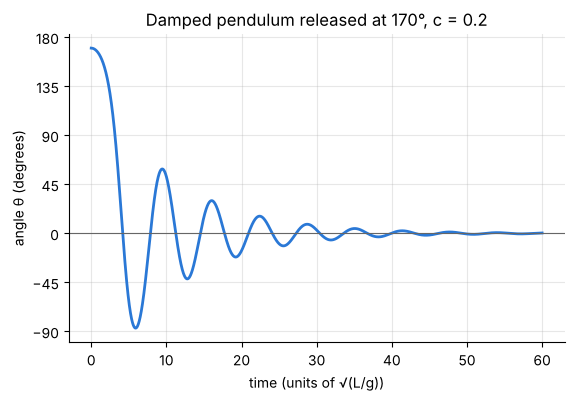

In [9]:
fig, ax = plt.subplots()
ax.plot(times, np.degrees(angle))
ax.axhline(0, color="0.4", lw=0.8)
ax.set(xlabel="time (units of √(L/g))", ylabel="angle θ (degrees)", title="Damped pendulum released at 170°, c = 0.2")
ax.set_yticks(np.arange(-90, 181, 45));

**Verify** with an energy balance. Multiplying the equation by $\dot\theta$ shows that the energy
$E = \tfrac12\dot\theta^2 + 1 - \cos\theta$ falls at the rate $c\,\dot\theta^2$, so the energy lost
must equal $c\int\dot\theta^2\,dt$. The solver knows nothing about energy, so this is an
independent check.

In [10]:
energy = speed**2 / 2 + 1 - np.cos(angle)
dissipated = 0.2 * trapezoid(speed**2, times)
print(f"energy lost: {energy[0] - energy[-1]:.6f}     dissipated by damping: {dissipated:.6f}")

assert abs((energy[0] - energy[-1]) - dissipated) < 1e-6
assert np.all(np.diff(energy) <= 1e-12)                    # the energy never increases
assert np.abs(angle).max() <= np.radians(170) + 1e-12      # so the pendulum never swings past its start

# late on the swings are small, and their zero crossings are spaced by half the period of the
# linearized equation, pi / sqrt(1 - c²/4)
late = times > 40
crossings = times[late][:-1][np.diff(np.sign(angle[late])) != 0]
assert np.allclose(np.diff(crossings), np.pi / np.sqrt(1 - 0.2**2 / 4), atol=0.02)

energy lost: 1.984788     dissipated by damping: 1.984788


**Answer.** The pendulum starts almost upright, so it lingers there, and the first swing takes
much longer than the later ones. Damping removes energy on every swing: the first swing reaches
only about 87° on the other side, and by $t = 60$ the amplitude is below 1°. As the swings
shrink, the motion approaches the decaying sinusoid of the linearized equation, with zero
crossings every $\pi/\sqrt{1 - c^2/4} \approx 3.16$ time units.

## Exercise 3

The Antoine equation is $\log_{10} P = A - B/(C + T)$. Derive $dP/dT$ symbolically, then
use `lambdify` to plot it for water ($A = 8.07131$, $B = 1730.63$, $C = 233.426$; $P$ in mmHg,
$T$ in °C) between 1 and 100 °C.

In [11]:
T, A, B, C = sp.symbols("T A B C", positive=True)

P = 10 ** (A - B / (C + T))
dPdT = sp.diff(P, T)
dPdT

        B            
  A - ─────          
      C + T          
10         ⋅B⋅log(10)
─────────────────────
             2       
      (C + T)        

In [12]:
water = {A: 8.07131, B: 1730.63, C: 233.426}
P_water = sp.lambdify(T, P.subs(water), "numpy")
slope_water = sp.lambdify(T, dPdT.subs(water), "numpy")

print(f"at 100 °C:  P = {P_water(100.0):.1f} mmHg     dP/dT = {slope_water(100.0):.2f} mmHg/°C")
print(f"at   1 °C:  P = {P_water(1.0):.2f} mmHg     dP/dT = {slope_water(1.0):.3f} mmHg/°C")

at 100 °C:  P = 760.1 mmHg     dP/dT = 27.24 mmHg/°C
at   1 °C:  P = 4.89 mmHg     dP/dT = 0.354 mmHg/°C


In [13]:
# verify: the hand result dP/dT = P ln(10) B / (C + T)², a central finite difference of P,
# and the normal boiling point (1 atm = 760 mmHg at 100 °C)
assert sp.simplify(dPdT - P * sp.log(10) * B / (C + T) ** 2) == 0

temperatures = np.linspace(1, 100, 200)
finite_diff = (P_water(temperatures + 1e-4) - P_water(temperatures - 1e-4)) / 2e-4
assert np.allclose(slope_water(temperatures), finite_diff, rtol=1e-6)
assert abs(P_water(100.0) - 760) < 1

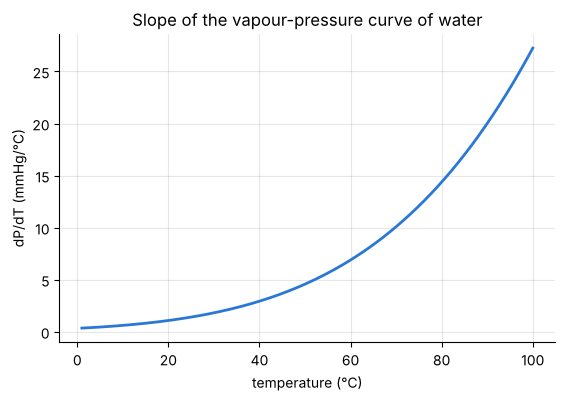

In [14]:
fig, ax = plt.subplots()
ax.plot(temperatures, slope_water(temperatures))
ax.set(xlabel="temperature (°C)", ylabel="dP/dT (mmHg/°C)", title="Slope of the vapour-pressure curve of water");

**Answer.** $\dfrac{dP}{dT} = \dfrac{B\ln 10}{(C+T)^2}\,10^{\,A - B/(C+T)} = \dfrac{B\ln 10}{(C+T)^2}\,P$.
For water the slope rises from 0.35 mmHg/°C at 1 °C to 27.2 mmHg/°C at 100 °C. Near the normal
boiling point a change of 1 °C therefore shifts the vapour pressure by about 3.6 %.

## Exercise 4

Generate C code for the van der Waals pressure and its two partial derivatives using `cse`
to share common subexpressions.

The van der Waals pressure is $P = \dfrac{RT}{V - b} - \dfrac{a}{V^2}$ (notebook 3), and its two
partial derivatives are $(\partial P/\partial T)_V$ and $(\partial P/\partial V)_T$.

In [15]:
R, T, V, a, b = sp.symbols("R T V a b", positive=True)
P_vdw = R * T / (V - b) - a / V**2

outputs = {"P": P_vdw, "dPdT": sp.diff(P_vdw, T), "dPdV": sp.diff(P_vdw, V)}
shared, reduced = sp.cse(list(outputs.values()))       # (shared pieces, expressions written with them)
shared, reduced

⎛⎡             ⎛    R ⎞⎤  ⎡       a         R⋅T   2⋅a⎤⎞
⎜⎢(x₀, V - b), ⎜x₁, ──⎟⎥, ⎢T⋅x₁ - ──, x₁, - ─── + ───⎥⎟
⎜⎣             ⎝    x₀⎠⎦  ⎢        2          2    3 ⎥⎟
⎝                         ⎣       V         x₀    V  ⎦⎠

In [16]:
# one C statement per shared piece, then one per output
for symbol, piece in shared:
    print("double", sp.ccode(piece, assign_to=symbol))
for name, expression in zip(outputs, reduced):
    print("double", sp.ccode(expression, assign_to=name))

double x0 = V - b;
double x1 = R/x0;
double P = T*x1 - a/pow(V, 2);
double dPdT = x1;
double dPdV = -R*T/pow(x0, 2) + 2*a/pow(V, 3);


In [17]:
# verify: putting the shared pieces back (last one first) recovers the original expressions,
# the derivatives match the hand results, and a = b = 0 gives the ideal gas
for name, expression in zip(outputs, reduced):
    for symbol, piece in reversed(shared):
        expression = expression.subs(symbol, piece)
    assert sp.simplify(expression - outputs[name]) == 0

assert sp.simplify(outputs["dPdT"] - R / (V - b)) == 0
assert sp.simplify(outputs["dPdV"] - (-R * T / (V - b) ** 2 + 2 * a / V**3)) == 0
assert sp.simplify(outputs["dPdV"].subs({a: 0, b: 0}) + R * T / V**2) == 0

**Answer.** `cse` finds two shared pieces, $x_0 = V - b$ and $x_1 = R/x_0$, and the three results
become $P = T x_1 - a/V^2$, $(\partial P/\partial T)_V = x_1$ and
$(\partial P/\partial V)_T = -RT/x_0^2 + 2a/V^3$. The five printed lines are valid C statements,
in the order they must be executed, and can be pasted into a function body (with `math.h`
included for `pow`).